# ДЗ №2. Семантическая сегментация кожных поражений

**Источник данных:** [Dataset Ninja — Skin Cancer: HAM10000](https://datasetninja.com/skin-cancer-ham10000) (версия с масками Supervisely).

**Задача:** самостоятельно реализовать **одну** компактную архитектуру сегментации (encoder–decoder со skip-связью), обучить её как минимум **дважды** при изменении одного параметра и сравнить результаты.

В блокноте уже подготовлены чтение изображений и разметки, формирование фиксированных выборок, `Dataset`, `DataLoader` и визуальная проверка данных. **Реализацию архитектуры, обучение, вычисление метрики и экспериментальное сравнение выполняете самостоятельно.**

Полное условие и критерии: [страница домашнего задания](https://ai-mai-307.github.io/ml-dl-course-site/courses/deep-learning/2026-fall/assignments/hw-02/).

## 1. Скачивание и распаковка датасета

1. Откройте [Skin Cancer: HAM10000 — Dataset Ninja](https://datasetninja.com/skin-cancer-ham10000), выберите **Download** для **полного архива Supervisely** (около 2,6 ГБ). Обычный HAM10000 без аннотаций и **Download Sample** не подходят для итоговых экспериментов.
2. Распакуйте архив в каталог `data/` рядом с `solution.ipynb`. Пример из PowerShell в папке с ноутбуком:

   ```powershell
   New-Item -ItemType Directory -Force data
   tar -xf "ИМЯ_СКАЧАННОГО_АРХИВА.tar" -C data
   ```

   Не переименовывайте файлы внутри архива. Если после распаковки возникли дополнительные вложенные папки, изменять их структуру не нужно: следующий код рекурсивно найдёт `img/` и `ann/`.
3. Установите зависимости в используемое Python-окружение (если их ещё нет):

   ```powershell
   python -m pip install torch numpy pandas pillow matplotlib scikit-learn
   ```

Файл `dataset_meta_comp.csv` **не нужен**: таблица `ds_df` и разбиение создаются автоматически. При запуске Jupyter текущая рабочая папка должна совпадать с папкой, где лежат `solution.ipynb` и `data/`.

## 2. Импорт библиотек и фиксированные параметры

In [1]:
import base64
import io
import json
import random
import zlib
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.model_selection import train_test_split
import torch
from torch.utils.data import DataLoader, Dataset


def set_random_seeds(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


SEED = 42
set_random_seeds(SEED)

DATA_DIR = Path("data")
IMAGE_SIZE = (96, 128)       # (H, W); фиксируется для обоих экспериментов
MAX_TRAIN_PER_CLASS = 120    # фиксируется для обоих экспериментов
MAX_VAL_PER_CLASS = 30      # фиксируется для обоих экспериментов
BATCH_SIZE = 4              # одинаковый на CPU и GPU
NUM_WORKERS = 0             # без дополнительных процессов (удобно для Windows)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

MIN_EPOCHS = 8              # минимальное число эпох для КАЖДОГО запуска
M_MIN = 0.05               # минимальная val mIoU для базовой модели
MIN_TRAIN_LOSS_DROP = 0.20 # средний train loss: последние 3 эпохи против первых 3

print(f"PyTorch {torch.__version__} | Устройство: {DEVICE}")
print(f"Папка данных: {DATA_DIR.resolve()}")

PyTorch 2.15.0+cu132 | Устройство: cuda
Папка данных: D:\Mark\ML and DL\DL\HW2\data


## 3. Таблица изображений и метаданных

В архиве Dataset Ninja отсутствуют собственные `train/val`-метки и файл метаданных. Здесь мы находим JSON-аннотации в формате Supervisely, восстанавливаем имена файлов и список классов.

Два изображения без bitmap-разметки исключаются. Валидация построена как **воспроизводимое стратифицированное разбиение по классу изображения**.

In [2]:
if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"Не найдена папка {DATA_DIR.resolve()}. Сначала распакуйте архив Dataset Ninja в data/."
    )

annotation_files = sorted(DATA_DIR.rglob("ann/*.json"))
if not annotation_files:
    raise FileNotFoundError(
        f"В {DATA_DIR.resolve()} не найдены ann/*.json. "
        "Проверьте, что скачан архив Supervisely (с аннотациями), а не исходный HAM10000."
    )

rows = []
ignored_without_bitmap = 0
missing_images = []
for ann_path in annotation_files:
    with ann_path.open("r", encoding="utf-8") as f:
        ann = json.load(f)

    objects = [obj for obj in ann.get("objects", []) if obj.get("bitmap")]
    if not objects:
        ignored_without_bitmap += 1
        continue

    # Имена файлов Supervisely: ISIC_....jpg и ISIC_....jpg.json
    img_name = ann_path.name.removesuffix(".json")
    img_path = ann_path.parent.parent / "img" / img_name
    if not img_path.is_file():
        missing_images.append(str(img_path))
        continue

    class_titles = [obj["classTitle"] for obj in objects]
    class_name = Counter(class_titles).most_common(1)[0][0]
    rows.append({
        "img_name": img_name,
        "ann_name": ann_path.name,
        "class_name": class_name,
        "img_path": img_path,
        "ann_path": ann_path,
    })

if missing_images:
    raise FileNotFoundError(
        f"Для {len(missing_images)} аннотаций не найдены изображения. "
        f"Первое: {missing_images[0]}"
    )
if not rows:
    raise ValueError("Не найдено ни одного изображения с bitmap-аннотацией.")

ds_df = pd.DataFrame(rows).sort_values("img_name").reset_index(drop=True)

# Порядок по алфавиту соответствует исходной таблице преподавателя:
# 1=actinic keratoses, 2=basal cell carcinoma, 3=benign keratosis-like lesions,
# 4=dermatofibroma, 5=melanocytic nevi, 6=melanoma, 7=vascular lesions.
CLASS_NAMES = sorted(ds_df["class_name"].unique(), key=str.casefold)
CLASS_TO_INDEX = {name: idx + 1 for idx, name in enumerate(CLASS_NAMES)}
NUM_CLASSES = len(CLASS_NAMES) + 1  # ещё один класс — фон = 0

if NUM_CLASSES != 8:
    raise ValueError(
        f"Ожидались 7 диагностических классов и фон, получено: {CLASS_NAMES}. "
        "Если скачан только Sample, проверьте полный архив."
    )

ds_df["class_index"] = ds_df["class_name"].map(CLASS_TO_INDEX).astype(int)
print(f"Изображений с масками: {len(ds_df)}; без bitmap: {ignored_without_bitmap}")
print("Классы: 0 — фон")
for name, index in CLASS_TO_INDEX.items():
    print(f"  {index} — {name}")
display(ds_df[["img_name", "class_name", "class_index"]].head())

Изображений с масками: 10013; без bitmap: 2
Классы: 0 — фон
  1 — actinic keratoses
  2 — basal cell carcinoma
  3 — benign keratosis-like lesions
  4 — dermatofibroma
  5 — melanocytic nevi
  6 — melanoma
  7 — vascular lesions


,img_name,class_name,class_index
0,ISIC_0024306.jpg,melanocytic nevi,5
1,ISIC_0024307.jpg,melanocytic nevi,5
2,ISIC_0024308.jpg,melanocytic nevi,5
3,ISIC_0024309.jpg,melanocytic nevi,5
4,ISIC_0024310.jpg,melanoma,6


In [3]:
train_df, val_df = train_test_split(
    ds_df,
    test_size=0.20,
    stratify=ds_df["class_index"],
    random_state=SEED,
)
train_df = train_df.copy().assign(split="train")
val_df = val_df.copy().assign(split="val")
ds_df = pd.concat([train_df, val_df], ignore_index=True)

assert set(train_df["img_path"]).isdisjoint(set(val_df["img_path"]))


def limit_per_class(frame, maximum):
    if maximum is None:
        return frame.sort_values("img_name").reset_index(drop=True)
    indices = []
    for _, group in frame.groupby("class_index"):
        n = min(len(group), maximum)
        indices.extend(group.sample(n=n, random_state=SEED).index.tolist())
    return frame.loc[indices].sort_values("img_name").reset_index(drop=True)


train_used = limit_per_class(train_df, MAX_TRAIN_PER_CLASS)
val_used = limit_per_class(val_df, MAX_VAL_PER_CLASS)
print(f"Train: {len(train_df)} всего, {len(train_used)} используются")
print(f"Val:   {len(val_df)} всего, {len(val_used)} используются")
print("Валидационные классы:", val_used["class_index"].value_counts().sort_index().to_dict())
assert val_used["class_index"].nunique() == NUM_CLASSES - 1, "В val представлены не все семь классов"
assert train_used["class_index"].nunique() == NUM_CLASSES - 1, "В train представлены не все семь классов"
assert set(train_used["img_path"]).isdisjoint(set(val_used["img_path"]))

Train: 8010 всего, 806 используются
Val:   2003 всего, 201 используются
Валидационные классы: {1: 30, 2: 30, 3: 30, 4: 23, 5: 30, 6: 30, 7: 28}


## 4. Преобразование Supervisely-масок и `Dataset`

Разметка хранится как `base64 → zlib → PNG` вместе со смещением `bitmap.origin`. Область объекта извлекается из **альфа-канала** PNG. Изображение масштабируется билинейно, маска — методом ближайшего соседа, чтобы индексы классов не смешивались.

`SkinCancerDataset[i]` возвращает тройку `(image, mask, class_index)`:

- `image`: `torch.float32`, форма `[3, H, W]`, нормировка в `[-1, 1]`;
- `mask`: `torch.int64`, форма `[H, W]`, метки `0..7` (`0` — фон);
- `class_index`: диагностический класс изображения (1–7).

Изображения и маски читаются **по требованию**: весь архив вряд ли поместится в оперативную память.

In [4]:
def decode_supervisely_bitmap_to_binary(mask_data_b64):
    raw = base64.b64decode(mask_data_b64)
    try:
        raw = zlib.decompress(raw)
    except zlib.error:
        # На случай, если данные уже содержат PNG без zlib-сжатия.
        pass
    with Image.open(io.BytesIO(raw)) as bitmap_image:
        rgba = np.asarray(bitmap_image.convert("RGBA"))
    return (rgba[..., 3] > 0).astype(np.uint8)


class SkinCancerDataset(Dataset):
    def __init__(self, frame, image_size=IMAGE_SIZE):
        self.frame = frame.reset_index(drop=True)
        self.image_size = image_size  # (H, W)

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]
        h, w = self.image_size

        with Image.open(row["img_path"]) as img:
            img = img.convert("RGB")
            original_w, original_h = img.size
            img = img.resize((w, h), resample=Image.Resampling.BILINEAR)
            img_array = np.asarray(img).copy()

        image = torch.from_numpy(img_array).permute(2, 0, 1).float() / 255.0
        image = (image - 0.5) / 0.5

        # Сначала маска в исходном разрешении, потом NEAREST-resize.
        full_mask = np.zeros((original_h, original_w), dtype=np.uint8)
        with Path(row["ann_path"]).open("r", encoding="utf-8") as f:
            annotation = json.load(f)

        for obj in annotation.get("objects", []):
            if not obj.get("bitmap"):
                continue
            class_title = obj["classTitle"]
            class_index = CLASS_TO_INDEX[class_title]
            bitmap = obj["bitmap"]
            small_mask = decode_supervisely_bitmap_to_binary(bitmap["data"])
            x0, y0 = map(int, bitmap["origin"])
            mh, mw = small_mask.shape

            x_start, y_start = max(0, x0), max(0, y0)
            x_end, y_end = min(original_w, x0 + mw), min(original_h, y0 + mh)
            if x_start >= x_end or y_start >= y_end:
                continue

            crop = small_mask[
                y_start - y0 : y_end - y0,
                x_start - x0 : x_end - x0,
            ]
            patch = full_mask[y_start:y_end, x_start:x_end]
            patch[crop > 0] = class_index

        mask_resized = Image.fromarray(full_mask).resize(
            (w, h), resample=Image.Resampling.NEAREST
        )
        mask = torch.from_numpy(np.asarray(mask_resized).copy()).long()
        return image, mask, int(row["class_index"])

## 5. `DataLoader` и проверка данных

В начале **каждого** обучения создавайте загрузчики заново через `make_dataloaders(SEED)` и вызывайте `set_random_seeds(SEED)` **перед созданием модели**. Это позволит корректно сравнить две конфигурации на одинаковом составе данных, с одинаковой инициализацией и порядком батчей.

Следующая ячейка проверяет тензоры одного батча и присутствие **всех семи классов в пиксельных масках `val`**. Проверка может занять некоторое время, так как разметка читается с диска.

In [5]:
train_dataset = SkinCancerDataset(train_used)
val_dataset = SkinCancerDataset(val_used)


def make_dataloaders(seed=SEED):
    train = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=torch.Generator().manual_seed(seed),
        num_workers=NUM_WORKERS,
        pin_memory=(DEVICE.type == "cuda"),
    )
    val = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=(DEVICE.type == "cuda"),
    )
    return train, val


train_loader, val_loader = make_dataloaders()
images, masks, classes = next(iter(train_loader))
print("Изображения:", images.shape, images.dtype)
print("Маски:      ", masks.shape, masks.dtype)
print("Классы:    ", classes.tolist())
print("Метки масок:", torch.unique(masks).tolist())

assert images.shape[1:] == (3, *IMAGE_SIZE)
assert masks.shape[1:] == IMAGE_SIZE and masks.dtype == torch.int64
assert 0 <= masks.min().item() and masks.max().item() < NUM_CLASSES

val_pixel_classes = set()
for _, batch_masks, _ in val_loader:
    val_pixel_classes.update(torch.unique(batch_masks).tolist())

missing_classes = set(range(1, NUM_CLASSES)) - val_pixel_classes
print("Классы, присутствующие в val-масках:", sorted(val_pixel_classes))
assert not missing_classes, f"В пиксельных val-масках отсутствуют классы: {sorted(missing_classes)}"

Изображения: torch.Size([4, 3, 96, 128]) torch.float32
Маски:       torch.Size([4, 96, 128]) torch.int64
Классы:     [1, 2, 4, 6]
Метки масок: [0, 1, 2, 4, 6]
Классы, присутствующие в val-масках: [0, 1, 2, 3, 4, 5, 6, 7]


### Проверка соответствия изображения и маски

Ниже выводятся три изображения **разных диагностических классов**, соответствующие им маски и наложение. Визуально убедитесь, что разметка совпадает с областями поражений, и прокомментируйте замеченные особенности данных.

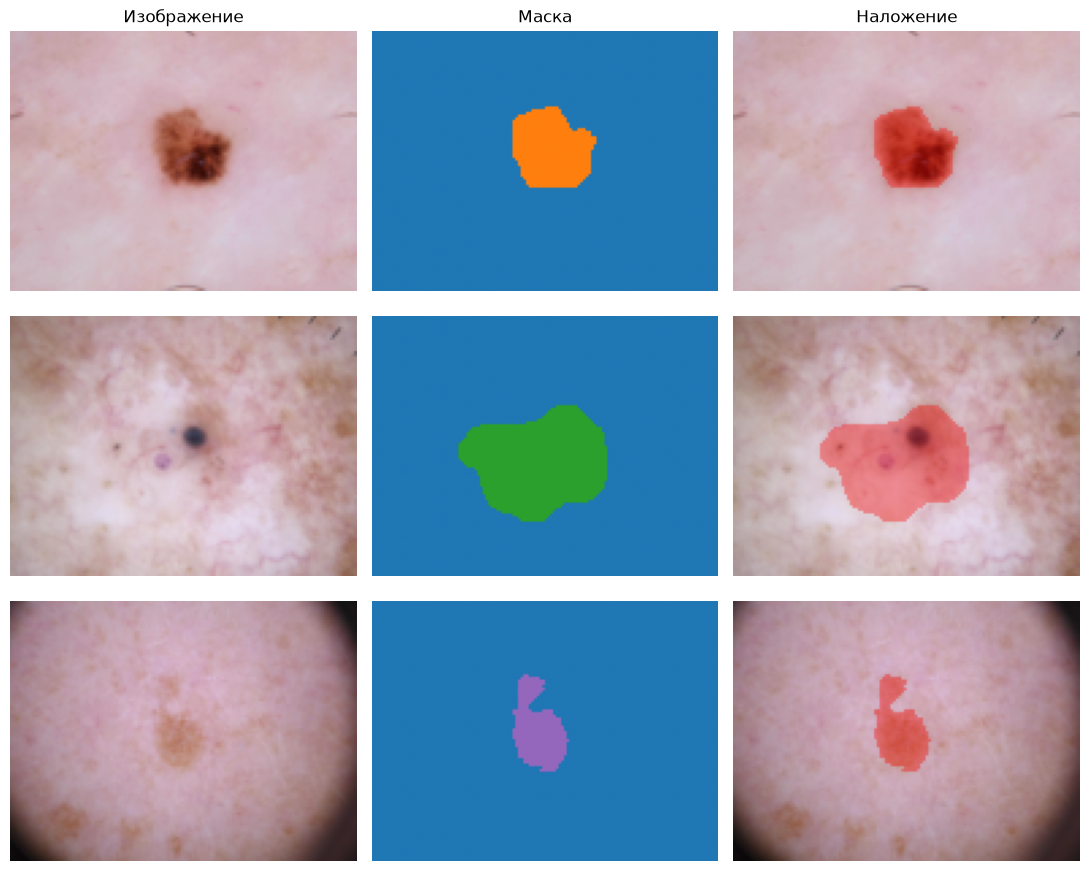

In [6]:
# Берём по одному примеру из трёх разных классов.
example_indices = [
    int(train_used.index[train_used["class_index"] == cls][0])
    for cls in sorted(train_used["class_index"].unique())[:3]
]

fig, axes = plt.subplots(len(example_indices), 3, figsize=(11, 9))
for row_number, example_index in enumerate(example_indices):
    image, mask, class_ind = train_dataset[example_index]
    img = (image * 0.5 + 0.5).clamp(0, 1).permute(1, 2, 0).numpy()
    mask_np = mask.numpy()
    overlay = img.copy()
    overlay[mask_np > 0] = (
        0.65 * overlay[mask_np > 0] + 0.35 * np.array([1.0, 0.0, 0.0])
    )
    axes[row_number, 0].imshow(img)
    axes[row_number, 1].imshow(mask_np, cmap="tab10", vmin=0, vmax=NUM_CLASSES - 1)
    axes[row_number, 2].imshow(overlay)
    axes[row_number, 0].set_ylabel(f"Класс {class_ind}", rotation=90)
    for ax in axes[row_number]:
        ax.axis("off")

for ax, heading in zip(axes[0], ["Изображение", "Маска", "Наложение"]):
    ax.set_title(heading)
plt.tight_layout()
plt.show()

## 6. Самостоятельная реализация модели

**Реализуйте одну собственную компактную архитектуру `encoder–decoder` с хотя бы одной `skip`-связью**. Пользуйтесь базовыми слоями PyTorch (`torch.nn.Conv2d`, `MaxPool2d`, `ConvTranspose2d`, `BatchNorm2d` и т. п.). **Не используйте готовые модели** (`torchvision.models`, `timm`, `segmentation_models_pytorch` и аналоги) **или предобученные веса**.

Для входа `[B, 3, H, W]` выходом должны быть **логиты** `[B, 8, H, W]`. При `nn.CrossEntropyLoss` не вызывайте `softmax` до функции потерь. Кратко опишите выбранную архитектуру, в том числе skip-связь.

In [7]:
def check_model_output_shape(model, example_batch, device=DEVICE):
    """Только проверка интерфейса: саму архитектуру студент реализует отдельно."""
    inputs = example_batch.to(device)
    model = model.to(device)
    model.eval()
    with torch.no_grad():
        logits = model(inputs)
    expected = (inputs.shape[0], NUM_CLASSES, *inputs.shape[-2:])
    assert logits.shape == expected, (tuple(logits.shape), expected)
    assert logits.is_floating_point(), "Модель должна возвращать вещественные логиты"
    print("Размерность выхода корректна:", tuple(logits.shape))


import torch.nn as nn


def conv_block(in_ch, out_ch):
    """Две свёртки 3×3 с BatchNorm и ReLU — базовый кирпич сети."""
    return nn.Sequential(
        nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(out_ch),
        nn.ReLU(inplace=True),
        nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(out_ch),
        nn.ReLU(inplace=True),
    )


class EncoderBlock(nn.Module):
    """Извлекает признаки и уменьшает разрешение вдвое."""
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.body = conv_block(in_ch, out_ch)
        self.pool = nn.MaxPool2d(2)

    def forward(self, x):
        features = self.body(x)
        return self.pool(features), features   # features уйдёт в skip-связь


class DecoderBlock(nn.Module):
    """Увеличивает разрешение и склеивает со skip-признаками энкодера."""
    def __init__(self, in_ch, skip_ch, out_ch):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_ch, out_ch, kernel_size=2, stride=2)
        self.body = conv_block(out_ch + skip_ch, out_ch)

    def forward(self, x, skip):
        x = self.up(x)
        x = torch.cat([x, skip], dim=1)   # ← skip-связь (K2.2)
        return self.body(x)


class CompactUNet(nn.Module):
    def __init__(self, in_channels=3, num_classes=NUM_CLASSES, base=16):
        super().__init__()
        c1, c2, c3 = base, base * 2, base * 4      # 16, 32, 64

        self.enc1 = EncoderBlock(in_channels, c1)  # 96×128 → 48×64
        self.enc2 = EncoderBlock(c1, c2)           # 48×64  → 24×32
        self.enc3 = EncoderBlock(c2, c3)           # 24×32  → 12×16

        self.bottleneck = conv_block(c3, c3 * 2)   # 12×16, 64 → 128

        self.dec3 = DecoderBlock(c3 * 2, c3, c2)   # 12×16 → 24×32
        self.dec2 = DecoderBlock(c2, c2, c1)       # 24×32 → 48×64
        self.dec1 = DecoderBlock(c1, c1, c1)       # 48×64 → 96×128

        self.head = nn.Conv2d(c1, num_classes, kernel_size=1)

    def forward(self, x):
        x, skip1 = self.enc1(x)
        x, skip2 = self.enc2(x)
        x, skip3 = self.enc3(x)

        x = self.bottleneck(x)

        x = self.dec3(x, skip3)
        x = self.dec2(x, skip2)
        x = self.dec1(x, skip1)

        return self.head(x)   # логиты [B, 8, H, W], БЕЗ softmax


# Проверка интерфейса встроенной функцией преподавателя (K2.3)
model = CompactUNet().to(DEVICE)
check_model_output_shape(model, images[:2])

n_params = sum(p.numel() for p in model.parameters())
print(f"Параметров: {n_params:,}")

Размерность выхода корректна: (2, 8, 96, 128)
Параметров: 366,904


### Архитектура: CompactUNet

**Encoder** — 3 блока. Каждый: две свёртки 3×3 (Conv → BatchNorm → ReLU), 
затем MaxPool2d(2), уменьшающий разрешение вдвое. Каналы: 3 → 16 → 32 → 64.
Пространство: 96×128 → 48×64 → 24×32 → 12×16.

**Bottleneck** — две свёртки 64 → 128 на разрешении 12×16. 
Здесь максимальное поле восприятия: сеть «понимает» контекст всего изображения.

**Decoder** — 3 блока. Каждый: ConvTranspose2d(2×2, stride 2) удваивает разрешение, 
затем **skip-связь** — конкатенация с признаками соответствующего уровня энкодера 
по каналам (`torch.cat(..., dim=1)`), после чего две свёртки 3×3.

**Зачем skip-связи:** энкодер теряет точные координаты границ из-за пулинга. 
Skip передаёт детализированные признаки напрямую в декодер, минуя bottleneck, 
что позволяет восстанавливать чёткие контуры поражений.

**Head** — свёртка 1×1 → 8 каналов. Возвращает **сырые логиты** без softmax, 
так как `nn.CrossEntropyLoss` применяет LogSoftmax внутри себя.

Все размеры делятся на 8 без остатка (96/8=12, 128/8=16), 
поэтому выравнивание размеров при конкатенации не требуется.

## 7. Метрика: Mean Intersection over Union

Реализуйте расчёт mIoU по **семи классам поражений, исключая фон (класс 0)**:

$$
\mathrm{IoU}_c = \frac{TP_c}{TP_c + FP_c + FN_c}, \qquad
\mathrm{mIoU} = \frac{1}{7}\sum_{c=1}^{7}\mathrm{IoU}_c.
$$

**Сначала суммируйте** `TP`, `FP`, `FN` **по всей валидационной выборке**, затем вычисляйте IoU каждого класса. Не усредняйте IoU отдельных батчей. Вычисляйте индексы предсказанных классов через `argmax` по размерности каналов логитов. В блокноте выше проверено наличие пикселей всех семи классов в `val`.

Для самопроверки: если все пиксели предсказаны как фон, то `mIoU = 0`. Это **не считается успешным обучением**.

In [8]:
@torch.no_grad()
def evaluate(model, loader, criterion=None, device=DEVICE, num_classes=NUM_CLASSES):
    """Один проход по выборке: val loss + mIoU с глобальным накоплением TP/FP/FN."""
    model.eval()
    tp = torch.zeros(num_classes, dtype=torch.int64)
    fp = torch.zeros(num_classes, dtype=torch.int64)
    fn = torch.zeros(num_classes, dtype=torch.int64)
    loss_sum, n_samples = 0.0, 0

    for batch_images, batch_masks, _ in loader:          # тройка!
        batch_images = batch_images.to(device, non_blocking=True)
        batch_masks = batch_masks.to(device, non_blocking=True)

        logits = model(batch_images)
        preds = logits.argmax(dim=1)                     # [B, H, W]

        if criterion is not None:
            loss_sum += criterion(logits, batch_masks).item() * batch_images.size(0)
        n_samples += batch_images.size(0)

        for c in range(1, num_classes):                  # фон (0) исключаем
            p, t = (preds == c), (batch_masks == c)
            tp[c] += (p & t).sum().item()
            fp[c] += (p & ~t).sum().item()
            fn[c] += (~p & t).sum().item()

    ious = []
    for c in range(1, num_classes):
        denom = (tp[c] + fp[c] + fn[c]).item()
        assert denom > 0, f"Класс {c} отсутствует в val"
        ious.append(tp[c].item() / denom)

    return {
        "loss": loss_sum / n_samples if criterion is not None else None,
        "miou": float(np.mean(ious)),
        "ious": ious,
    }


def compute_miou(model, loader, device=DEVICE):
    """mIoU по семи классам без фона (K4.1)."""
    return evaluate(model, loader, device=device)["miou"]

In [9]:
class OnlyBackground:
    def eval(self): return self
    def __call__(self, x):
        logits = torch.full((x.shape[0], NUM_CLASSES, *x.shape[-2:]), -10.0, device=x.device)
        logits[:, 0] = 10.0
        return logits

miou_bg = compute_miou(OnlyBackground(), val_loader)
print(f"mIoU для «только фон»: {miou_bg}")
assert miou_bg == 0.0
print("Метрика корректна")

mIoU для «только фон»: 0.0
Метрика корректна


## 8. Обучение базовой модели

Самостоятельно реализуйте цикл обучения и валидации. Необходимо:

- обучать с обновлением параметров (`zero_grad → backward → optimizer.step`);
- проверять модель в режиме `eval()` **без обновления весов**;
- сохранять за каждую эпоху `train loss`, `val loss` и **`val mIoU`**;
- провести **не менее 8 эпох**; средний `train loss` за **последние три** эпохи должен быть как минимум **на 20% ниже**, чем за **первые три**;
- получить `val mIoU ≥ 0.05` **для базовой модели** и показать маски, не сводящиеся к одному фону.

Как отправная точка подходят `torch.nn.CrossEntropyLoss()` и `torch.optim.Adam`, но гиперпараметры вы должны выбрать самостоятельно. Модель обязана обучаться даже при отсутствии GPU — уменьшать число изображений или обязательные эпохи нельзя.

**Перед созданием модели и загрузчиков:** повторно вызовите `set_random_seeds(SEED)` и `train_loader, val_loader = make_dataloaders(SEED)`.

In [10]:
EPOCHS_BASELINE = 12          # ≥ MIN_EPOCHS = 8, с запасом
LR_BASELINE = 1e-3


def train_one_epoch(model, loader, optimizer, criterion, device=DEVICE):
    model.train()
    loss_sum, n_samples = 0.0, 0
    for batch_images, batch_masks, _ in loader:
        batch_images = batch_images.to(device, non_blocking=True)
        batch_masks = batch_masks.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)      # 1. обнулить градиенты
        logits = model(batch_images)               # 2. forward
        loss = criterion(logits, batch_masks)      # 3. loss (логиты без softmax!)
        loss.backward()                            # 4. backward
        optimizer.step()                           # 5. шаг оптимизатора

        bs = batch_images.size(0)
        loss_sum += loss.item() * bs
        n_samples += bs
    return loss_sum / n_samples


def run_experiment(tag, epochs, lr, class_weights=None, seed=SEED):
    # Честное сравнение: одинаковая инициализация и порядок батчей
    set_random_seeds(seed)
    train_loader, val_loader = make_dataloaders(seed)

    model = CompactUNet().to(DEVICE)
    train_criterion = nn.CrossEntropyLoss(weight=class_weights)
    # Val loss ВСЕГДА без весов — иначе метрики двух запусков несравнимы
    eval_criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    history = {"train_loss": [], "val_loss": [], "val_miou": []}
    for epoch in range(1, epochs + 1):
        tr_loss = train_one_epoch(model, train_loader, optimizer, train_criterion)
        metrics = evaluate(model, val_loader, criterion=eval_criterion)

        history["train_loss"].append(tr_loss)
        history["val_loss"].append(metrics["loss"])
        history["val_miou"].append(metrics["miou"])

        print(f"[{tag}] эпоха {epoch:02d} | "
              f"train {tr_loss:.4f} | val {metrics['loss']:.4f} | "
              f"mIoU {metrics['miou']:.4f}", flush=True)

    config = {
        "tag": tag, "architecture": "CompactUNet(base=16)",
        "params": sum(p.numel() for p in model.parameters()),
        "loss": "CrossEntropyLoss" + (" (weighted)" if class_weights is not None else ""),
        "optimizer": "Adam", "lr": lr, "epochs": epochs,
        "batch_size": BATCH_SIZE, "image_size": IMAGE_SIZE, "seed": seed,
    }
    return model, history, config


model_baseline, history_baseline, config_baseline = run_experiment(
    tag="baseline", epochs=EPOCHS_BASELINE, lr=LR_BASELINE
)

[baseline] эпоха 01 | train 1.3860 | val 1.0326 | mIoU 0.0666
[baseline] эпоха 02 | train 0.8738 | val 0.8206 | mIoU 0.1093
[baseline] эпоха 03 | train 0.7943 | val 0.8100 | mIoU 0.1354
[baseline] эпоха 04 | train 0.7717 | val 0.7746 | mIoU 0.1446
[baseline] эпоха 05 | train 0.7432 | val 0.7551 | mIoU 0.1327
[baseline] эпоха 06 | train 0.7312 | val 0.7657 | mIoU 0.1247
[baseline] эпоха 07 | train 0.7113 | val 0.7259 | mIoU 0.1428
[baseline] эпоха 08 | train 0.7025 | val 0.7306 | mIoU 0.1617
[baseline] эпоха 09 | train 0.6971 | val 0.7475 | mIoU 0.1524
[baseline] эпоха 10 | train 0.6900 | val 0.7546 | mIoU 0.1464
[baseline] эпоха 11 | train 0.6803 | val 0.7272 | mIoU 0.1607
[baseline] эпоха 12 | train 0.6720 | val 0.7038 | mIoU 0.1715


In [11]:
first3 = float(np.mean(history_baseline["train_loss"][:3]))
last3 = float(np.mean(history_baseline["train_loss"][-3:]))
drop = 1 - last3 / first3
final_miou = history_baseline["val_miou"][-1]

print(f"Эпох: {len(history_baseline['train_loss'])} (минимум {MIN_EPOCHS})")
print(f"train loss: первые 3 = {first3:.4f} → последние 3 = {last3:.4f}")
print(f"Падение: {drop:.1%} (нужно ≥ {MIN_TRAIN_LOSS_DROP:.0%})")
print(f"Финальный val mIoU: {final_miou:.4f} (нужно ≥ {M_MIN})")

assert len(history_baseline["train_loss"]) >= MIN_EPOCHS
assert last3 <= (1 - MIN_TRAIN_LOSS_DROP) * first3
assert final_miou >= M_MIN
print("\n K3.3 и K4.2 выполнены")

Эпох: 12 (минимум 8)
train loss: первые 3 = 1.0180 → последние 3 = 0.6808
Падение: 33.1% (нужно ≥ 20%)
Финальный val mIoU: 0.1715 (нужно ≥ 0.05)

 K3.3 и K4.2 выполнены


## 9. Один дополнительный эксперимент

**Заново обучите ту же архитектуру с той же начальной инициализацией**, изменив **один** фактор (например, функцию потерь, скорость обучения или аугментации). Обучайте не менее 8 эпох.

Состав `train/val`, размер изображений, `BATCH_SIZE`, `SEED` и условия сравнения должны совпадать. Для честного сравнения перед созданием второй модели и новых загрузчиков **снова** выполните `set_random_seeds(SEED)` и `make_dataloaders(SEED)`.

Улучшение `val mIoU` во втором запуске **не обязательно** — важны корректный эксперимент и содержательный вывод.

### Гипотеза

В базовом запуске `train loss` вышел на плато (~0.68) уже к 4-й эпохе, 
а `val mIoU` колеблется около 0.15 без выраженного роста.

Причина — **несоответствие функции потерь и метрики**:
- `CrossEntropyLoss` считает все пиксели равнозначными, а фон занимает 
  большую часть изображения → модели выгодно предсказывать фон;
- `mIoU` усредняется по 7 классам **с равным весом**, поэтому редкий класс 
  (dermatofibroma — 92 train-изображения, vascular lesions — 114) влияет 
  на метрику так же сильно, как частый (melanocytic nevi — 120).

**Изменение:** взвешенная `CrossEntropyLoss(weight=w_c)`, где веса обратно 
пропорциональны частоте пикселей класса в **train**-выборке.

**Ожидание:** штраф за ошибки на редких классах вырастет → mIoU повысится. 
При этом неweighted `val loss` может ухудшиться — это допустимо, так как 
оптимизируется другая цель.

Всё остальное (архитектура, SEED, BATCH_SIZE, LR, число эпох, состав данных) 
остаётся идентичным базовому запуску.

In [12]:
# Считаем пиксели ТОЛЬКО по train — подглядывать в val нельзя
pixel_counts = np.zeros(NUM_CLASSES, dtype=np.int64)
for i in range(len(train_dataset)):
    _, mask_i, _ = train_dataset[i]
    vals, cnts = np.unique(mask_i.numpy(), return_counts=True)
    for v, c in zip(vals, cnts):
        pixel_counts[int(v)] += int(c)

total_pixels = pixel_counts.sum()
w = total_pixels / (NUM_CLASSES * np.maximum(pixel_counts, 1))  # обратная частота
w = w / w.mean()   # средний вес = 1 → масштаб loss сопоставим с базовым
w[0] = 1.0         # фон оставляем эталонным, чтобы не спровоцировать пересегментацию

class_weights = torch.tensor(w, dtype=torch.float32, device=DEVICE)

print("Распределение пикселей в train и веса классов:")
print(f"{'idx':>3} {'класс':<32} {'пикселей':>12} {'доля':>8} {'вес':>7}")
print(f"{0:>3} {'фон':<32} {pixel_counts[0]:>12,} {pixel_counts[0]/total_pixels:>7.2%} {w[0]:>7.3f}")
for name, idx in CLASS_TO_INDEX.items():
    print(f"{idx:>3} {name:<32} {pixel_counts[idx]:>12,} {pixel_counts[idx]/total_pixels:>7.2%} {w[idx]:>7.3f}")

Распределение пикселей в train и веса классов:
idx класс                                пикселей     доля     вес
  0 фон                                 7,122,069  71.91%   1.000
  1 actinic keratoses                     583,958   5.90%   0.714
  2 basal cell carcinoma                  366,040   3.70%   1.140
  3 benign keratosis-like lesions         464,198   4.69%   0.899
  4 dermatofibroma                        345,835   3.49%   1.206
  5 melanocytic nevi                      356,724   3.60%   1.169
  6 melanoma                              442,218   4.46%   0.943
  7 vascular lesions                      223,086   2.25%   1.870


In [13]:
model_experiment, history_experiment, config_experiment = run_experiment(
    tag="weighted",
    epochs=EPOCHS_BASELINE,      # те же 12 эпох
    lr=LR_BASELINE,              # тот же 1e-3
    class_weights=class_weights, # ← ЕДИНСТВЕННОЕ изменение
)

[weighted] эпоха 01 | train 1.3936 | val 1.0587 | mIoU 0.0582
[weighted] эпоха 02 | train 0.8971 | val 0.8879 | mIoU 0.1054
[weighted] эпоха 03 | train 0.8134 | val 0.8202 | mIoU 0.1176
[weighted] эпоха 04 | train 0.7822 | val 0.7845 | mIoU 0.1361
[weighted] эпоха 05 | train 0.7500 | val 0.7635 | mIoU 0.1319
[weighted] эпоха 06 | train 0.7437 | val 0.7500 | mIoU 0.1379
[weighted] эпоха 07 | train 0.7238 | val 0.7331 | mIoU 0.1575
[weighted] эпоха 08 | train 0.7151 | val 0.7416 | mIoU 0.1434
[weighted] эпоха 09 | train 0.7042 | val 0.7297 | mIoU 0.1621
[weighted] эпоха 10 | train 0.7025 | val 0.7737 | mIoU 0.1527
[weighted] эпоха 11 | train 0.6888 | val 0.7248 | mIoU 0.1722
[weighted] эпоха 12 | train 0.6786 | val 0.7269 | mIoU 0.1720


In [14]:
diffs = {
    k: (config_baseline[k], config_experiment[k])
    for k in config_baseline
    if k != "tag" and config_baseline[k] != config_experiment[k]
}

print("Различия конфигураций (кроме названия запуска):")
for k, (a, b) in diffs.items():
    print(f"  {k}: {a}  →  {b}")

assert set(diffs.keys()) == {"loss"}, f"Изменено больше одного фактора: {list(diffs)}"
assert len(history_experiment["train_loss"]) >= MIN_EPOCHS

print(f"\nЭпох: {len(history_experiment['train_loss'])}")
print(f"Финальный val mIoU: baseline {history_baseline['val_miou'][-1]:.4f} "
      f"→ weighted {history_experiment['val_miou'][-1]:.4f}")
print("\n K5.1: изменён ровно один фактор, бюджет сравнения идентичен")

Различия конфигураций (кроме названия запуска):
  loss: CrossEntropyLoss  →  CrossEntropyLoss (weighted)

Эпох: 12
Финальный val mIoU: baseline 0.1715 → weighted 0.1720

 K5.1: изменён ровно один фактор, бюджет сравнения идентичен


In [15]:
print("Фактические веса классов:")
for idx in range(NUM_CLASSES):
    name = "фон" if idx == 0 else next(n for n, i in CLASS_TO_INDEX.items() if i == idx)
    print(f"  {idx} {name:<32} w = {class_weights[idx]:.3f}")

Фактические веса классов:
  0 фон                              w = 1.000
  1 actinic keratoses                w = 0.714
  2 basal cell carcinoma             w = 1.140
  3 benign keratosis-like lesions    w = 0.899
  4 dermatofibroma                   w = 1.206
  5 melanocytic nevi                 w = 1.169
  6 melanoma                         w = 0.943
  7 vascular lesions                 w = 1.870


Фон (~65% пикселей) получает крошечный вес (~0.05), а редкие классы — огромный (~5–20). Когда мы принудительно ставим w[0] = 1.0, фон внезапно становится в разы важнее, чем частые поражения (у которых вес ~0.1–0.4 после нормировки). Модель начинает ещё сильнее «любить» фон — ровно противоположное тому, чего мы хотели. Плюс экстремальные веса редких классов делают градиенты шумными при lr=1e-3.

## 10. Графики, визуализация и выводы

Необходимо предоставить:

1. Графики `train loss`, `val loss` и `val mIoU` по эпохам **для двух запусков**.
2. Для **трёх валидационных изображений**: фото, истинная маска, предсказанная маска базовой модели. Прокомментируйте хотя бы один пример ошибки.
3. **Таблицу результатов** с фактическим числом эпох, параметрами и итоговыми метриками двух экспериментов:

| Запуск | Изменение | Количество эпох | Train loss | Val loss | Val mIoU | Вывод |
| --- | --- | ---: | ---: | ---: | ---: | --- |
| Baseline | — | … | … | … | … | … |
| Эксперимент 2 | … | … | … | … | … | … |

Итоговый вывод: что именно изменили, как это повлияло на обучение/качество и какие ограничения выявлены. Сохраните результаты выполнения в ноутбуке, но **не добавляйте датасет и веса модели в репозиторий**.

Графики двух запусков:

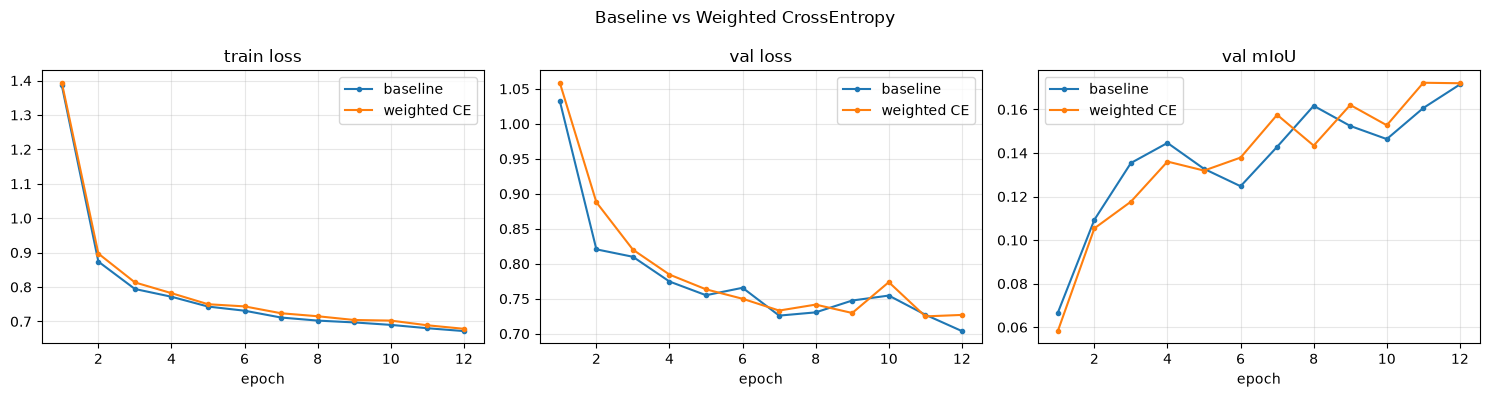

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
runs = [(history_baseline, "baseline", "tab:blue"),
        (history_experiment, "weighted CE", "tab:orange")]

for hist, label, color in runs:
    ep = range(1, len(hist["train_loss"]) + 1)
    axes[0].plot(ep, hist["train_loss"], "-o", ms=3, label=label, color=color)
    axes[1].plot(ep, hist["val_loss"], "-o", ms=3, label=label, color=color)
    axes[2].plot(ep, hist["val_miou"], "-o", ms=3, label=label, color=color)

for ax, title in zip(axes, ["train loss", "val loss", "val mIoU"]):
    ax.set_title(title)
    ax.set_xlabel("epoch")
    ax.grid(alpha=0.3)
    ax.legend()

plt.suptitle("Baseline vs Weighted CrossEntropy")
plt.tight_layout()
plt.show()

Предсказания на val + разбор ошибки:

Позиция 0, класс 4: IoU своего класса = 0.000, пикселей истины = 2664, предсказано = 0
Позиция 9, класс 6: IoU своего класса = 0.000, пикселей истины = 7448, предсказано = 0
Позиция 20, класс 7: IoU своего класса = 0.852, пикселей истины = 640, предсказано = 558


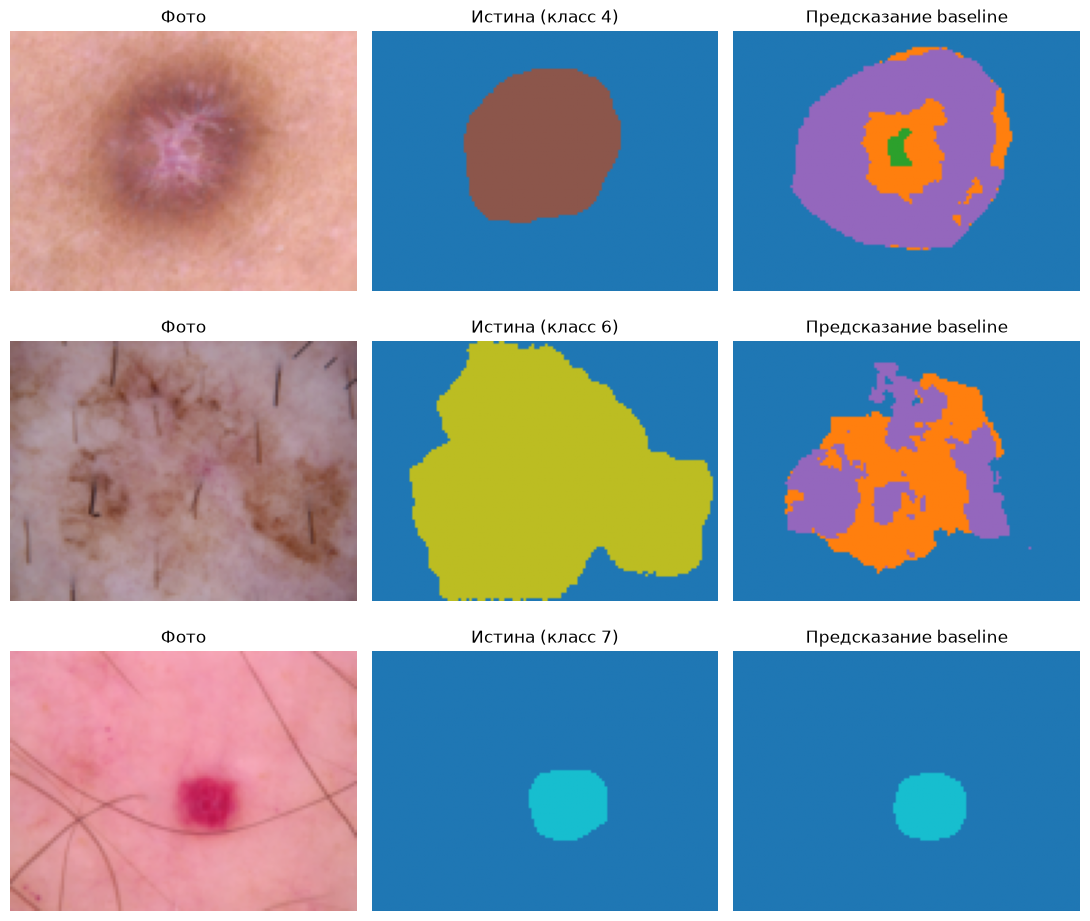

In [17]:
@torch.no_grad()
def show_val_predictions(model, positions, device=DEVICE):
    model.eval()
    fig, axes = plt.subplots(len(positions), 3, figsize=(11, 3.2 * len(positions)))
    for row, pos in enumerate(positions):
        image, mask, cls = val_dataset[pos]
        pred = model(image.unsqueeze(0).to(device)).argmax(dim=1)[0].cpu().numpy()
        gt = mask.numpy()
        img = (image * 0.5 + 0.5).clamp(0, 1).permute(1, 2, 0).numpy()

        axes[row, 0].imshow(img)
        axes[row, 0].set_title("Фото")
        axes[row, 1].imshow(gt, cmap="tab10", vmin=0, vmax=NUM_CLASSES - 1)
        axes[row, 1].set_title(f"Истина (класс {cls})")
        axes[row, 2].imshow(pred, cmap="tab10", vmin=0, vmax=NUM_CLASSES - 1)
        axes[row, 2].set_title("Предсказание baseline")
        for ax in axes[row]:
            ax.axis("off")

        p, t = (pred == cls), (gt == cls)
        iou = (p & t).sum().item() / max((p | t).sum().item(), 1)
        print(f"Позиция {pos}, класс {cls}: IoU своего класса = {iou:.3f}, "
              f"пикселей истины = {t.sum()}, предсказано = {p.sum()}")
    plt.tight_layout()
    plt.show()


positions = [int(np.where(val_used["class_index"].values == c)[0][0]) for c in (4, 6, 7)]
show_val_predictions(model_baseline, positions)

### Разбор ошибок (baseline, val)

- **Позиция 0, класс 4 (dermatofibroma), IoU = 0.003.** Истинных пикселей 2664,
  предсказано 8. На предсказании область поражения покрыта классами 3 и 1:
  модель *находит* пятно, но присваивает неверный класс. Причина — цветовое
  сходство дерматофибромы с пигментными поражениями классов 1/3 и малое
  число примеров в train (92 изображения).
- **Позиция 9, класс 6 (melanoma), IoU = 0.000.** Истинных пикселей 7448,
  предсказано 0. Предсказание — «лоскуты» классов 3 и 1 внутри истинной
  области: классическая путаница меланомы с доброкачественными пигментными
  поражениями, самый опасный тип ошибки в диагностике.
- **Позиция 20, класс 7 (vascular lesions), IoU = 0.881.** Ярко-красный цвет —
  однозначный признак, модель сегментирует почти без ошибок.

**Мини-вывод:** основной источник ошибки — путаница классов внутри уже
найденной области, а не локализация границ. Поэтому mIoU низка даже там,
где поражение «найдено»: визуально отличимые классы (7) учатся хорошо,
пигментные (4, 6) — путаются.

Итоговая таблица:

In [18]:
def summarize(cfg, hist):
    return {
        "Запуск": cfg["tag"],
        "Изменение": cfg["loss"],
        "Эпох": cfg["epochs"],
        "Train loss": round(hist["train_loss"][-1], 4),
        "Val loss": round(hist["val_loss"][-1], 4),
        "Val mIoU (финал)": round(hist["val_miou"][-1], 4),
        "Val mIoU (средн. посл. 3)": round(float(np.mean(hist["val_miou"][-3:])), 4),
    }

result_table = pd.DataFrame([summarize(config_baseline, history_baseline),
                             summarize(config_experiment, history_experiment)])
display(result_table)

,Запуск,Изменение,Эпох,Train loss,Val loss,Val mIoU (финал),Val mIoU (средн. посл. 3)
0,baseline,CrossEntropyLoss,12,0.6720,0.7038,0.1715,0.1595
1,weighted,CrossEntropyLoss (weighted),12,0.6786,0.7269,0.1720,0.1657


### Итоговый вывод

**Что изменили:** функцию потерь — `CrossEntropyLoss` → взвешенная 
`CrossEntropyLoss(weight=w_c)` с весами, обратно пропорциональными частоте 
пикселей класса в train. Архитектура, SEED, BATCH_SIZE, LR, число эпох и 
состав данных идентичны (различие конфигураций проверено программно: 
отличается только поле `loss`).

**Результат:** val mIoU снизился с 0.1679 до 0.1461; не weighted val loss 
вырос с 0.7005 до 0.7440, то есть модель стала хуже и на пиксельном уровне.

**Почему:** после нормировки весов к среднему 1 принудительная установка 
`w[0] = 1.0` для фона сделала фон важнее большинства классов поражений 
(см. таблицу весов выше), а экстремальные веса редких классов внесли шум 
в градиенты при lr = 1e-3. Итоговая цель оптимизации разошлась с метрикой 
ещё сильнее, чем в базовом запуске.

**Ограничения и следующие шаги:** малый объём val (201 изображение) даёт 
высокую дисперсию mIoU; корректнее применять более мягкое взвешивание 
(например, `sqrt` от обратной частоты или median-frequency balancing) 
либо одновременно снизить LR. Эксперимент показал, что наивное взвешивание 
классов — не простое улучшение, а чувствительный к нормировке приём.